# OREX vs NEO-REX raw nsteps plots

Notebook minimale: carica i CSV recuperati dai log e plotta solo le metriche grezze in funzione di `nsteps`, senza rescaling/collapse/fit.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')

BASE_DIR = Path('plot/orex_recovered_from_txt')
if not BASE_DIR.exists():
    BASE_DIR = Path('.')

OREX_CSV = BASE_DIR / 'recovered_orex_metrics.csv'
NEOREX_CSV = BASE_DIR / 'recovered_neorex_eval_metrics.csv'
OUT_DIR = BASE_DIR

OREX_CSV, NEOREX_CSV, OUT_DIR

(PosixPath('recovered_orex_metrics.csv'),
 PosixPath('recovered_neorex_eval_metrics.csv'),
 PosixPath('.'))

In [2]:
def load_metrics(path):
    frame = pd.read_csv(path)
    numeric_cols = [
        'world_size', 'nreplicas', 'nsteps', 'swap_acceptance', 'total_accepted',
        'total_proposed', 'work_mean', 'work_sem', 'work_count',
        'thermalization_s', 'measurement_s', 'total_s', 'flow_applied_updates',
    ]
    for col in numeric_cols:
        if col in frame.columns:
            frame[col] = pd.to_numeric(frame[col], errors='coerce')
    if 'swap_acceptance_sem' not in frame.columns:
        frame['swap_acceptance_sem'] = np.sqrt(
            frame['swap_acceptance'] * (1.0 - frame['swap_acceptance']) / frame['total_proposed']
        )
    return frame.sort_values(['nreplicas', 'nsteps']).reset_index(drop=True)

orex = load_metrics(OREX_CSV)
neorex = load_metrics(NEOREX_CSV)

orex['algorithm'] = 'OREX'
neorex['algorithm'] = 'NEO-REX pretrained'
raw = pd.concat([orex, neorex], ignore_index=True, sort=False)
raw[['algorithm', 'nreplicas', 'nsteps', 'swap_acceptance', 'swap_acceptance_sem', 'work_mean', 'work_sem']]

,algorithm,nreplicas,nsteps,swap_acceptance,swap_acceptance_sem,work_mean,work_sem
0,OREX,4,0,0.010286,0.000515,15.468660,0.035250
1,OREX,4,2,0.058750,0.001200,7.980036,0.023260
2,OREX,4,4,0.166354,0.001900,4.105233,0.015910
3,OREX,4,6,0.259323,0.002237,2.735193,0.012750
4,OREX,4,8,0.322604,0.002386,2.069812,0.010870
5,OREX,8,0,0.247355,0.001441,2.858547,0.008452
6,OREX,8,2,0.423315,0.001651,1.362651,0.005909
7,OREX,8,4,0.557723,0.001659,0.715913,0.004192
8,OREX,8,6,0.625156,0.001617,0.492444,0.003431
9,OREX,8,8,0.667913,0.001573,0.381195,0.002983


In [3]:
def by_algorithm_replica(frame):
    for (algorithm, nrep), sub in frame.groupby(['algorithm', 'nreplicas'], sort=True):
        yield algorithm, int(nrep), sub.sort_values('nsteps')


def savefig(fig, name):
    png = OUT_DIR / f'{name}.png'
    pdf = OUT_DIR / f'{name}.pdf'
    fig.savefig(png, dpi=180, bbox_inches='tight')
    fig.savefig(pdf, bbox_inches='tight')
    return png, pdf

replica_colors = {
    4: 'tab:blue',
    8: 'tab:orange',
    12: 'tab:green',
    16: 'tab:red',
}

algorithm_styles = {
    'OREX': {'marker': 'o', 'linestyle': '-'},
    'NEO-REX pretrained': {'marker': 's', 'linestyle': '--'},
}

# Backward-compatible name used by later cells.
styles = algorithm_styles


def plot_style(algorithm, nrep):
    base = algorithm_styles.get(algorithm, {'marker': 'o', 'linestyle': '-'})
    return {
        'marker': base['marker'],
        'linestyle': base['linestyle'],
        'color': replica_colors.get(int(nrep), None),
    }

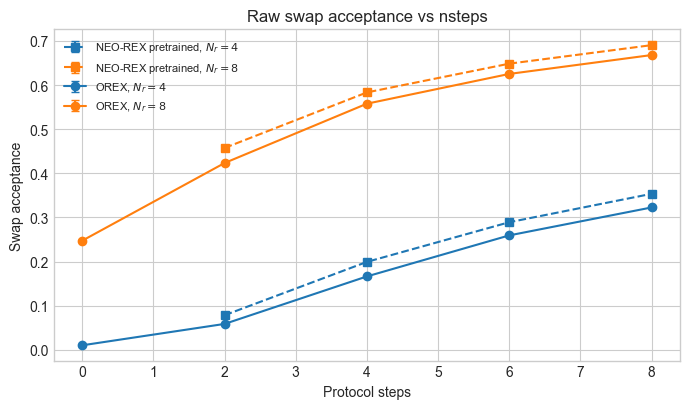

In [4]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
for algorithm, nrep, sub in by_algorithm_replica(raw):
    style = plot_style(algorithm, nrep)
    ax.errorbar(
        sub['nsteps'],
        sub['swap_acceptance'],
        yerr=sub['swap_acceptance_sem'],
        marker=style['marker'],
        linestyle=style['linestyle'],
        color=style['color'],
        capsize=3,
        label=f'{algorithm}, $N_r={nrep}$',
    )
ax.set_xlabel('Protocol steps')
ax.set_ylabel('Swap acceptance')
ax.set_title('Raw swap acceptance vs nsteps')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
savefig(fig, 'raw_acceptance_vs_nsteps_orex_neorex')
plt.show()

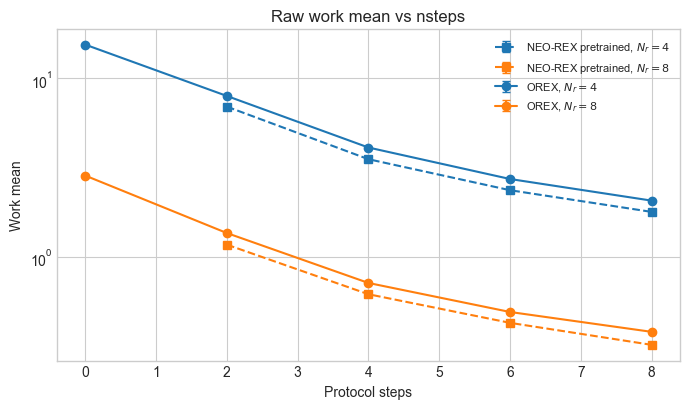

In [5]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
for algorithm, nrep, sub in by_algorithm_replica(raw):
    style = plot_style(algorithm, nrep)
    ax.errorbar(
        sub['nsteps'],
        sub['work_mean'],
        yerr=sub['work_sem'],
        marker=style['marker'],
        linestyle=style['linestyle'],
        color=style['color'],
        capsize=3,
        label=f'{algorithm}, $N_r={nrep}$',
    )
ax.set_xlabel('Protocol steps')
ax.set_ylabel('Work mean')
ax.set_yscale('log')
ax.set_title('Raw work mean vs nsteps')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
savefig(fig, 'raw_work_vs_nsteps_orex_neorex')
plt.show()

## Check a repliche fissate: $W \sim 1/nsteps$

Qui controllo prima la cosa più elementare: fissato `N_r` e algoritmo, il lavoro dovrebbe scalare come

\[
W(nsteps) \simeq \frac{A}{nsteps}.
\]

Quindi `W*nsteps` dovrebbe essere circa costante. Uso solo `nsteps > 0`.

In [6]:
scaling_check = raw[raw['nsteps'] > 0].copy()
scaling_check['work_times_nsteps'] = scaling_check['work_mean'] * scaling_check['nsteps']
scaling_check['work_times_nsteps_sem'] = scaling_check['work_sem'] * scaling_check['nsteps']
scaling_check[['algorithm', 'nreplicas', 'nsteps', 'work_mean', 'work_sem', 'work_times_nsteps', 'work_times_nsteps_sem']]

,algorithm,nreplicas,nsteps,work_mean,work_sem,work_times_nsteps,work_times_nsteps_sem
1,OREX,4,2,7.980036,0.023260,15.960072,0.046520
2,OREX,4,4,4.105233,0.015910,16.420932,0.063640
3,OREX,4,6,2.735193,0.012750,16.411158,0.076500
4,OREX,4,8,2.069812,0.010870,16.558496,0.086960
6,OREX,8,2,1.362651,0.005909,2.725302,0.011818
7,OREX,8,4,0.715913,0.004192,2.863651,0.016768
8,OREX,8,6,0.492444,0.003431,2.954666,0.020586
9,OREX,8,8,0.381195,0.002983,3.049559,0.023864
10,NEO-REX pretrained,4,2,6.952978,0.021290,13.905956,0.042580
11,NEO-REX pretrained,4,4,3.530432,0.014540,14.121728,0.058160


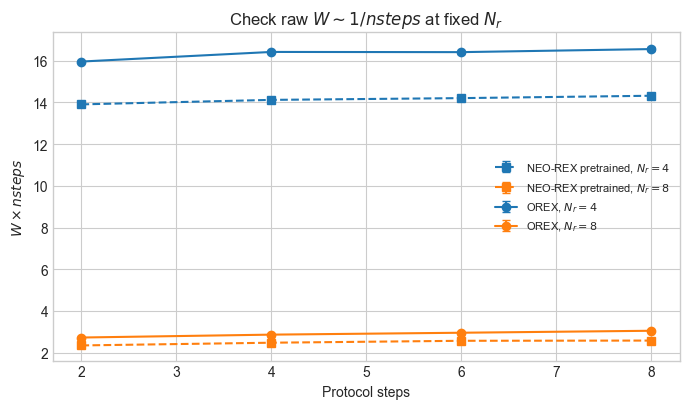

In [7]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
for algorithm, nrep, sub in by_algorithm_replica(scaling_check):
    style = plot_style(algorithm, nrep)
    ax.errorbar(
        sub['nsteps'],
        sub['work_times_nsteps'],
        yerr=sub['work_times_nsteps_sem'],
        marker=style['marker'],
        linestyle=style['linestyle'],
        color=style['color'],
        capsize=3,
        label=f'{algorithm}, $N_r={nrep}$',
    )
ax.set_xlabel('Protocol steps')
ax.set_ylabel(r'$W \times nsteps$')
ax.set_title(r'Check raw $W \sim 1/nsteps$ at fixed $N_r$')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
savefig(fig, 'raw_work_times_nsteps_check_orex_neorex')
plt.show()

In [8]:
def fixed_minus_one_fit(sub):
    n = sub['nsteps'].to_numpy(dtype=float)
    wmean = sub['work_mean'].to_numpy(dtype=float)
    wsem = sub['work_sem'].to_numpy(dtype=float)
    mask = np.isfinite(n) & np.isfinite(wmean) & np.isfinite(wsem) & (n > 0) & (wmean > 0) & (wsem > 0)
    n, wmean, wsem = n[mask], wmean[mask], wsem[mask]
    y = np.log(wmean)
    sigma_y = wsem / wmean
    x = np.log(n)
    # log W = log A - log nsteps. Only log A is fitted.
    weights = 1.0 / (sigma_y * sigma_y)
    logA = np.sum(weights * (y + x)) / np.sum(weights)
    residual = y - (logA - x)
    chi2 = np.sum(weights * residual * residual)
    dof = max(1, len(y) - 1)
    return {
        'A': float(np.exp(logA)),
        'logA': float(logA),
        'chi2_dof_fixed_slope': float(chi2 / dof),
        'mean_W_nsteps': float(np.mean(wmean * n)),
        'rel_spread_W_nsteps': float(np.std(wmean * n, ddof=1) / np.mean(wmean * n)) if len(wmean) > 1 else float('nan'),
        'n_points': int(len(wmean)),
    }

rows = []
for (algorithm, nrep), sub in scaling_check.groupby(['algorithm', 'nreplicas'], sort=True):
    fit = fixed_minus_one_fit(sub)
    fit.update({'algorithm': algorithm, 'nreplicas': int(nrep)})
    rows.append(fit)
fixed_nr_fit = pd.DataFrame(rows).sort_values(['algorithm', 'nreplicas']).reset_index(drop=True)
fixed_nr_fit

,A,logA,chi2_dof_fixed_slope,mean_W_nsteps,rel_spread_W_nsteps,n_points,algorithm,nreplicas
0,14.064132,2.643628,9.592837,14.138417,0.012374,4,NEO-REX pretrained,4
1,2.446143,0.894513,53.518392,2.492489,0.043318,4,NEO-REX pretrained,8
2,16.232557,2.787019,20.812029,16.337665,0.015949,4,OREX,4
3,2.840656,1.044035,69.139701,2.898295,0.047636,4,OREX,8


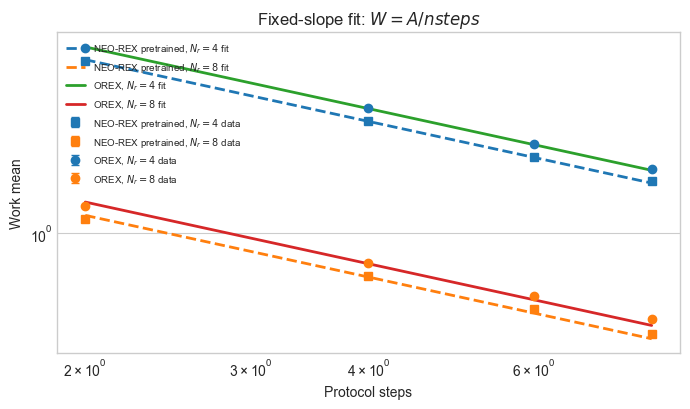

In [9]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
for algorithm, nrep, sub in by_algorithm_replica(scaling_check):
    style = plot_style(algorithm, nrep)
    fit = fixed_nr_fit[(fixed_nr_fit['algorithm'] == algorithm) & (fixed_nr_fit['nreplicas'] == nrep)].iloc[0]
    sub = sub.sort_values('nsteps')
    ax.errorbar(
        sub['nsteps'],
        sub['work_mean'],
        yerr=sub['work_sem'],
        marker=style['marker'],
        linestyle='none',
        color=style['color'],
        capsize=3,
        label=f'{algorithm}, $N_r={nrep}$ data',
    )
    xs = np.geomspace(sub['nsteps'].min(), sub['nsteps'].max(), 100)
    ax.plot(xs, fit['A'] / xs, linestyle=style['linestyle'], linewidth=2.0,
            label=f'{algorithm}, $N_r={nrep}$ fit')
ax.set_xlabel('Protocol steps')
ax.set_ylabel('Work mean')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title(r'Fixed-slope fit: $W=A/nsteps$')
ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
savefig(fig, 'raw_work_fixed_nr_inv_nsteps_fit_orex_neorex')
plt.show()

## Rapporto rispetto a nsteps=0

Uso il punto `nsteps=0` come baseline PT standard e plotto

\[
R(nsteps) = \frac{W(nsteps=0)}{W(nsteps)}.
\]

Per NEO-REX non abbiamo una run `nsteps=0`, quindi uso lo stesso baseline PT standard misurato nei dati OREX a pari `N_r`. Questo dovrebbe mostrare direttamente quanto il protocollo riduce il lavoro rispetto allo swap diretto e se il guadagno scala diversamente con il numero di repliche.

In [10]:
pt_baseline = orex[orex['nsteps'] == 0][[
    'nreplicas', 'work_mean', 'work_sem', 'swap_acceptance', 'swap_acceptance_sem'
]].copy()
pt_baseline = pt_baseline.rename(columns={
    'work_mean': 'work_mean_nsteps0',
    'work_sem': 'work_sem_nsteps0',
    'swap_acceptance': 'swap_acceptance_nsteps0',
    'swap_acceptance_sem': 'swap_acceptance_sem_nsteps0',
})

ratio_df = raw[raw['nsteps'] > 0].merge(pt_baseline, on='nreplicas', how='left')
ratio_df['work_ratio_to_nsteps0'] = ratio_df['work_mean_nsteps0'] / ratio_df['work_mean']
ratio_df['work_ratio_to_nsteps0_sem'] = ratio_df['work_ratio_to_nsteps0'] * np.sqrt(
    (ratio_df['work_sem_nsteps0'] / ratio_df['work_mean_nsteps0']) ** 2
    + (ratio_df['work_sem'] / ratio_df['work_mean']) ** 2
)
ratio_df['acceptance_ratio_to_nsteps0'] = ratio_df['swap_acceptance'] / ratio_df['swap_acceptance_nsteps0']
ratio_df['acceptance_ratio_to_nsteps0_sem'] = ratio_df['acceptance_ratio_to_nsteps0'] * np.sqrt(
    (ratio_df['swap_acceptance_sem_nsteps0'] / ratio_df['swap_acceptance_nsteps0']) ** 2
    + (ratio_df['swap_acceptance_sem'] / ratio_df['swap_acceptance']) ** 2
)

ratio_csv = OUT_DIR / 'raw_ratio_to_nsteps0_orex_neorex.csv'
ratio_df.to_csv(ratio_csv, index=False)
ratio_df[[
    'algorithm', 'nreplicas', 'nsteps', 'work_mean_nsteps0', 'work_mean',
    'work_ratio_to_nsteps0', 'work_ratio_to_nsteps0_sem',
    'swap_acceptance_nsteps0', 'swap_acceptance', 'acceptance_ratio_to_nsteps0'
]].sort_values(['algorithm', 'nreplicas', 'nsteps'])

,algorithm,nreplicas,nsteps,work_mean_nsteps0,work_mean,work_ratio_to_nsteps0,work_ratio_to_nsteps0_sem,swap_acceptance_nsteps0,swap_acceptance,acceptance_ratio_to_nsteps0
8,NEO-REX pretrained,4,2,15.468660,6.952978,2.224753,0.008492,0.010286,0.078464,7.628233
9,NEO-REX pretrained,4,4,15.468660,3.530432,4.381520,0.020623,0.010286,0.199271,19.373031
10,NEO-REX pretrained,4,6,15.468660,2.367685,6.533242,0.035702,0.010286,0.289141,28.110150
11,NEO-REX pretrained,4,8,15.468660,1.789984,8.641787,0.052901,0.010286,0.353490,34.366129
12,NEO-REX pretrained,8,2,2.858547,1.172992,2.436971,0.013611,0.247355,0.457455,1.849387
13,NEO-REX pretrained,8,4,2.858547,0.619129,4.617044,0.032466,0.247355,0.583281,2.358072
14,NEO-REX pretrained,8,6,2.858547,0.428084,6.677534,0.054259,0.247355,0.648393,2.621305
15,NEO-REX pretrained,8,8,2.858547,0.322369,8.867325,0.081047,0.247355,0.690379,2.791045
0,OREX,4,2,15.468660,7.980036,1.938420,0.007172,0.010286,0.058750,5.711647
1,OREX,4,4,15.468660,4.105233,3.768035,0.016941,0.010286,0.166354,16.172856


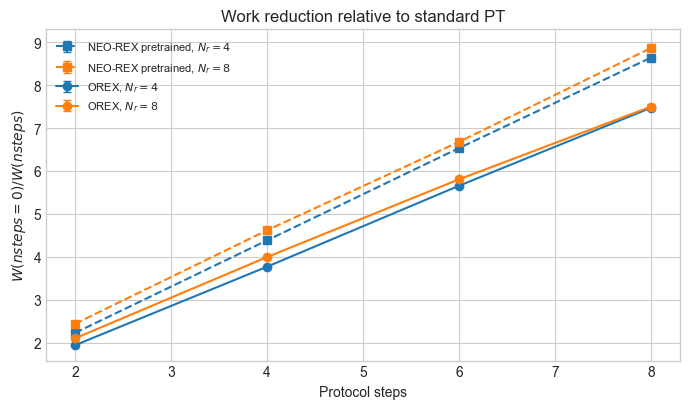

In [11]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
for algorithm, nrep, sub in by_algorithm_replica(ratio_df):
    style = plot_style(algorithm, nrep)
    sub = sub.sort_values('nsteps')
    ax.errorbar(
        sub['nsteps'],
        sub['work_ratio_to_nsteps0'],
        yerr=sub['work_ratio_to_nsteps0_sem'],
        marker=style['marker'],
        linestyle=style['linestyle'],
        color=style['color'],
        capsize=3,
        label=f'{algorithm}, $N_r={nrep}$',
    )
ax.set_xlabel('Protocol steps')
ax.set_ylabel(r'$W(nsteps=0) / W(nsteps)$')
ax.set_title('Work reduction relative to standard PT')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
savefig(fig, 'raw_work_ratio_to_nsteps0_orex_neorex')
plt.show()

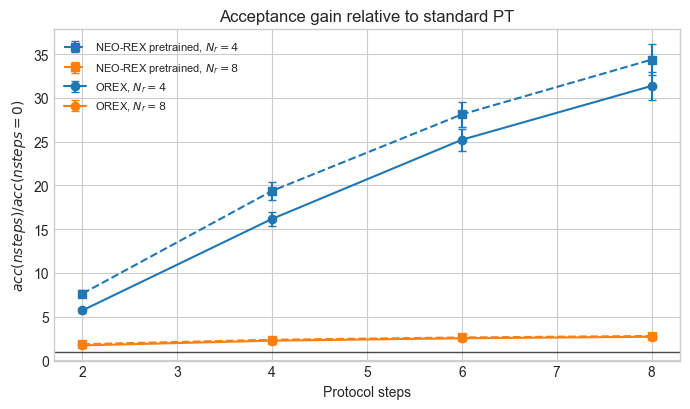

In [12]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
for algorithm, nrep, sub in by_algorithm_replica(ratio_df):
    style = plot_style(algorithm, nrep)
    sub = sub.sort_values('nsteps')
    ax.errorbar(
        sub['nsteps'],
        sub['acceptance_ratio_to_nsteps0'],
        yerr=sub['acceptance_ratio_to_nsteps0_sem'],
        marker=style['marker'],
        linestyle=style['linestyle'],
        color=style['color'],
        capsize=3,
        label=f'{algorithm}, $N_r={nrep}$',
    )
ax.axhline(1.0, color='k', linewidth=1.0, alpha=0.7)
ax.set_xlabel('Protocol steps')
ax.set_ylabel(r'$acc(nsteps) / acc(nsteps=0)$')
ax.set_title('Acceptance gain relative to standard PT')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
savefig(fig, 'raw_acceptance_ratio_to_nsteps0_orex_neorex')
plt.show()

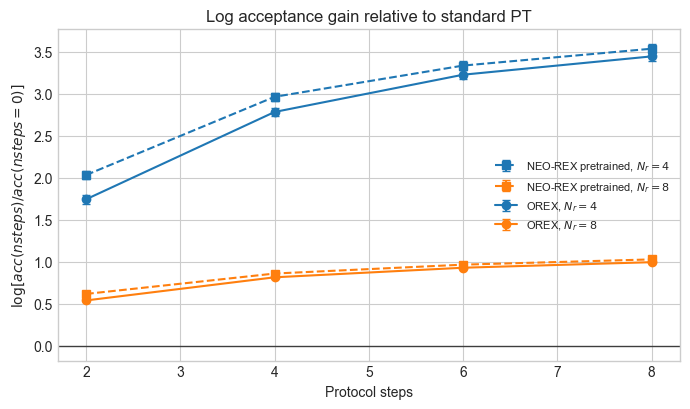

,algorithm,nreplicas,nsteps,swap_acceptance_nsteps0,swap_acceptance,acceptance_ratio_to_nsteps0,log_acceptance_gain_to_nsteps0,log_acceptance_gain_to_nsteps0_sem
8,NEO-REX pretrained,4,2,0.010286,0.078464,7.628233,2.031856,0.053024
9,NEO-REX pretrained,4,4,0.010286,0.199271,19.373031,2.963882,0.051092
10,NEO-REX pretrained,4,6,0.010286,0.289141,28.110150,3.336131,0.050693
11,NEO-REX pretrained,4,8,0.010286,0.353490,34.366129,3.537071,0.050531
12,NEO-REX pretrained,8,2,0.247355,0.457455,1.849387,0.614854,0.006870
13,NEO-REX pretrained,8,4,0.247355,0.583281,2.358072,0.857845,0.006476
14,NEO-REX pretrained,8,6,0.247355,0.648393,2.621305,0.963672,0.006325
15,NEO-REX pretrained,8,8,0.247355,0.690379,2.791045,1.026416,0.006242
0,OREX,4,2,0.010286,0.058750,5.711647,1.742507,0.054064
1,OREX,4,4,0.010286,0.166354,16.172856,2.783334,0.051344


In [13]:
ratio_df['log_acceptance_gain_to_nsteps0'] = np.log(
    ratio_df['swap_acceptance'] / ratio_df['swap_acceptance_nsteps0']
)
ratio_df['log_acceptance_gain_to_nsteps0_sem'] = np.sqrt(
    (ratio_df['swap_acceptance_sem_nsteps0'] / ratio_df['swap_acceptance_nsteps0']) ** 2
    + (ratio_df['swap_acceptance_sem'] / ratio_df['swap_acceptance']) ** 2
)

fig, ax = plt.subplots(figsize=(7.0, 4.2))
for algorithm, nrep, sub in by_algorithm_replica(ratio_df):
    style = plot_style(algorithm, nrep)
    sub = sub.sort_values('nsteps')
    ax.errorbar(
        sub['nsteps'],
        sub['log_acceptance_gain_to_nsteps0'],
        yerr=sub['log_acceptance_gain_to_nsteps0_sem'],
        marker=style['marker'],
        linestyle=style['linestyle'],
        color=style['color'],
        capsize=3,
        label=f'{algorithm}, $N_r={nrep}$',
    )
ax.axhline(0.0, color='k', linewidth=1.0, alpha=0.7)
ax.set_xlabel('Protocol steps')
ax.set_ylabel(r'$\log[acc(nsteps)/acc(nsteps=0)]$')
ax.set_title('Log acceptance gain relative to standard PT')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
savefig(fig, 'raw_log_acceptance_gain_to_nsteps0_orex_neorex')
plt.show()

ratio_df[[
    'algorithm', 'nreplicas', 'nsteps', 'swap_acceptance_nsteps0', 'swap_acceptance',
    'acceptance_ratio_to_nsteps0', 'log_acceptance_gain_to_nsteps0',
    'log_acceptance_gain_to_nsteps0_sem'
]].sort_values(['algorithm', 'nreplicas', 'nsteps'])

## Work globale della ladder

Qui parto dal `work_mean` locale per proposta di swap adiacente e costruisco due quantità aggregate semplici:

\[
(N_r-1)\,W
\]

che approssima la somma sui link della ladder, e

\[
N_r\,W
\]

che tiene conto del numero totale di repliche simulate. Sono diagnostiche diverse dal work locale.

In [14]:
global_work = raw[raw['nsteps'] > 0].copy()
global_work['work_times_nlinks'] = global_work['work_mean'] * (global_work['nreplicas'] - 1.0)
global_work['work_times_nlinks_sem'] = global_work['work_sem'] * (global_work['nreplicas'] - 1.0)
global_work['work_times_nreplicas'] = global_work['work_mean'] * global_work['nreplicas']
global_work['work_times_nreplicas_sem'] = global_work['work_sem'] * global_work['nreplicas']

global_work_csv = OUT_DIR / 'raw_global_ladder_work_orex_neorex.csv'
global_work.to_csv(global_work_csv, index=False)
global_work[[
    'algorithm', 'nreplicas', 'nsteps', 'work_mean', 'work_sem',
    'work_times_nlinks', 'work_times_nlinks_sem',
    'work_times_nreplicas', 'work_times_nreplicas_sem'
]].sort_values(['algorithm', 'nreplicas', 'nsteps'])

,algorithm,nreplicas,nsteps,work_mean,work_sem,work_times_nlinks,work_times_nlinks_sem,work_times_nreplicas,work_times_nreplicas_sem
10,NEO-REX pretrained,4,2,6.952978,0.021290,20.858934,0.063870,27.811912,0.085160
11,NEO-REX pretrained,4,4,3.530432,0.014540,10.591296,0.043620,14.121728,0.058160
12,NEO-REX pretrained,4,6,2.367685,0.011760,7.103055,0.035280,9.470740,0.047040
13,NEO-REX pretrained,4,8,1.789984,0.010170,5.369952,0.030510,7.159936,0.040680
14,NEO-REX pretrained,8,2,1.172992,0.005558,8.210944,0.038906,9.383936,0.044464
15,NEO-REX pretrained,8,4,0.619129,0.003950,4.333905,0.027650,4.953034,0.031600
16,NEO-REX pretrained,8,6,0.428084,0.003240,2.996589,0.022680,3.424674,0.025920
17,NEO-REX pretrained,8,8,0.322369,0.002788,2.256580,0.019516,2.578949,0.022304
1,OREX,4,2,7.980036,0.023260,23.940108,0.069780,31.920144,0.093040
2,OREX,4,4,4.105233,0.015910,12.315699,0.047730,16.420932,0.063640


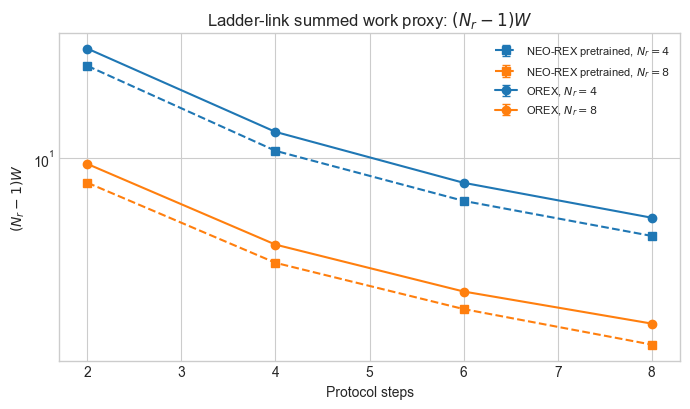

In [15]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
for algorithm, nrep, sub in by_algorithm_replica(global_work):
    style = plot_style(algorithm, nrep)
    sub = sub.sort_values('nsteps')
    ax.errorbar(
        sub['nsteps'],
        sub['work_times_nlinks'],
        yerr=sub['work_times_nlinks_sem'],
        marker=style['marker'],
        linestyle=style['linestyle'],
        color=style['color'],
        capsize=3,
        label=f'{algorithm}, $N_r={nrep}$',
    )
ax.set_xlabel('Protocol steps')
ax.set_ylabel(r'$(N_r-1) W$')
ax.set_yscale('log')
ax.set_title(r'Ladder-link summed work proxy: $(N_r-1)W$')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
savefig(fig, 'raw_work_times_nlinks_vs_nsteps_orex_neorex')
plt.show()

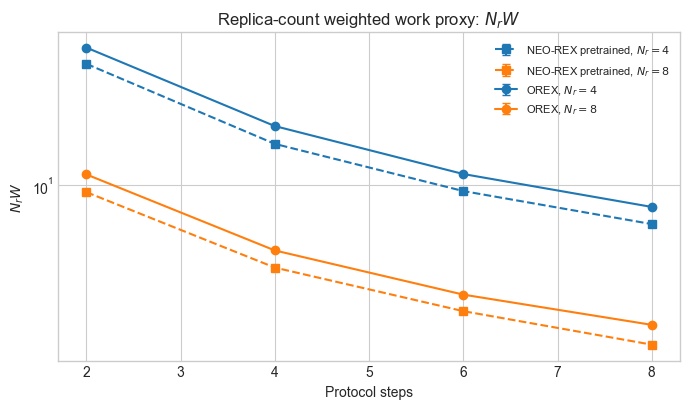

In [16]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
for algorithm, nrep, sub in by_algorithm_replica(global_work):
    style = plot_style(algorithm, nrep)
    sub = sub.sort_values('nsteps')
    ax.errorbar(
        sub['nsteps'],
        sub['work_times_nreplicas'],
        yerr=sub['work_times_nreplicas_sem'],
        marker=style['marker'],
        linestyle=style['linestyle'],
        color=style['color'],
        capsize=3,
        label=f'{algorithm}, $N_r={nrep}$',
    )
ax.set_xlabel('Protocol steps')
ax.set_ylabel(r'$N_r W$')
ax.set_yscale('log')
ax.set_title(r'Replica-count weighted work proxy: $N_r W$')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
savefig(fig, 'raw_work_times_nreplicas_vs_nsteps_orex_neorex')
plt.show()

## Fit empirico dominante: $W \sim 1/[nsteps (N_r-1)^2]$

Qui testo direttamente la legge che sembra emergere dai dati, senza termine PT e senza parametro `alpha`:

\[
W = \frac{C}{nsteps (N_r-1)^2}.
\]

Il fit ha solo una normalizzazione `C`, separata per algoritmo.

In [17]:
dominant = raw[raw['nsteps'] > 0].copy()
dominant['dominant_x'] = dominant['nsteps'] * (dominant['nreplicas'] - 1.0) ** 2
dominant['dominant_inv_x'] = 1.0 / dominant['dominant_x']


def fit_dominant_C(frame):
    x = frame['dominant_x'].to_numpy(dtype=float)
    work = frame['work_mean'].to_numpy(dtype=float)
    work_sem = frame['work_sem'].to_numpy(dtype=float)
    mask = np.isfinite(x) & np.isfinite(work) & np.isfinite(work_sem) & (x > 0) & (work_sem > 0)
    basis = 1.0 / x[mask]
    y = work[mask]
    sigma = work_sem[mask]
    weights = 1.0 / (sigma * sigma)
    C = float(np.sum(weights * basis * y) / np.sum(weights * basis * basis))
    pred = C * basis
    residual = y - pred
    chi2 = float(np.sum(weights * residual * residual))
    dof = max(1, len(y) - 1)
    return {
        'C': C,
        'chi2_dof': chi2 / dof,
        'mean_relative_residual': float(np.mean(residual / y)),
        'max_abs_relative_residual': float(np.max(np.abs(residual / y))),
        'rel_spread_Wx': float(np.std(y * x[mask], ddof=1) / np.mean(y * x[mask])) if len(y) > 1 else float('nan'),
        'n_points': int(len(y)),
    }

fit_rows = []
for algorithm, sub in dominant.groupby('algorithm', sort=True):
    fit = fit_dominant_C(sub)
    fit['algorithm'] = algorithm
    fit_rows.append(fit)

dominant_fits = pd.DataFrame(fit_rows).sort_values('algorithm').reset_index(drop=True)
dominant_fits

,C,chi2_dof,mean_relative_residual,max_abs_relative_residual,rel_spread_Wx,n_points,algorithm
0,124.317944,59.880481,0.001764,0.081466,0.036338,8,NEO-REX pretrained
1,143.657236,68.704568,0.004757,0.075763,0.037375,8,OREX


In [18]:
dominant = dominant.merge(dominant_fits[['algorithm', 'C']], on='algorithm', how='left')
dominant['dominant_prediction'] = dominant['C'] / dominant['dominant_x']
dominant['dominant_residual'] = dominant['work_mean'] - dominant['dominant_prediction']
dominant['dominant_relative_residual'] = dominant['dominant_residual'] / dominant['work_mean']
dominant['work_times_dominant_x'] = dominant['work_mean'] * dominant['dominant_x']
dominant['work_times_dominant_x_sem'] = dominant['work_sem'] * dominant['dominant_x']

dominant_csv = OUT_DIR / 'raw_dominant_work_scaling_nsteps_Nrminus1sq.csv'
dominant.to_csv(dominant_csv, index=False)
dominant_csv

PosixPath('raw_dominant_work_scaling_nsteps_Nrminus1sq.csv')

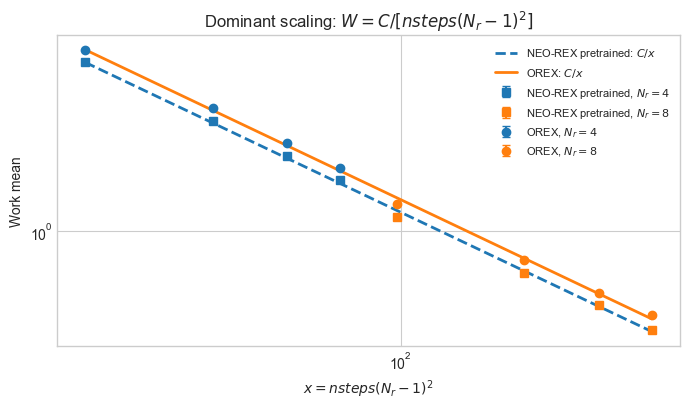

In [19]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
for algorithm, nrep, sub in by_algorithm_replica(dominant):
    style = plot_style(algorithm, nrep)
    sub = sub.sort_values('dominant_x')
    ax.errorbar(
        sub['dominant_x'],
        sub['work_mean'],
        yerr=sub['work_sem'],
        marker=style['marker'],
        linestyle='none',
        color=style['color'],
        capsize=3,
        label=f'{algorithm}, $N_r={nrep}$',
    )

xmin = float(dominant['dominant_x'].min())
xmax = float(dominant['dominant_x'].max())
xs = np.geomspace(xmin, xmax, 300)
for _, fit in dominant_fits.iterrows():
    algorithm = fit['algorithm']
    style = styles.get(algorithm, {'linestyle': '-'})
    ax.plot(xs, fit['C'] / xs, linestyle=style['linestyle'], linewidth=2.0,
            label=f'{algorithm}: $C/x$')

ax.set_xlabel(r'$x=nsteps (N_r-1)^2$')
ax.set_ylabel('Work mean')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title(r'Dominant scaling: $W=C/[nsteps (N_r-1)^2]$')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
savefig(fig, 'raw_dominant_work_scaling_nsteps_Nrminus1sq')
plt.show()

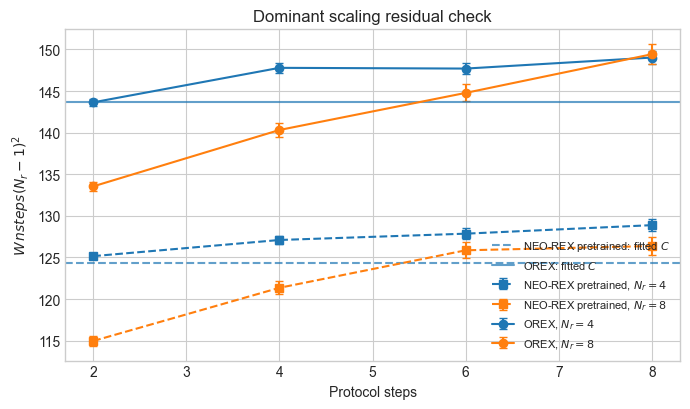

,algorithm,nreplicas,nsteps,dominant_x,C,dominant_prediction,work_mean,work_sem,dominant_relative_residual,work_times_dominant_x
8,NEO-REX pretrained,4,2,18.0,124.317944,6.906552,6.952978,0.021290,0.006677,125.153604
9,NEO-REX pretrained,4,4,36.0,124.317944,3.453276,3.530432,0.014540,0.021854,127.095552
10,NEO-REX pretrained,4,6,54.0,124.317944,2.302184,2.367685,0.011760,0.027665,127.854990
11,NEO-REX pretrained,4,8,72.0,124.317944,1.726638,1.789984,0.010170,0.035389,128.878848
12,NEO-REX pretrained,8,2,98.0,124.317944,1.268550,1.172992,0.005558,-0.081466,114.953216
13,NEO-REX pretrained,8,4,196.0,124.317944,0.634275,0.619129,0.003950,-0.024463,121.349343
14,NEO-REX pretrained,8,6,294.0,124.317944,0.422850,0.428084,0.003240,0.012227,125.856755
15,NEO-REX pretrained,8,8,392.0,124.317944,0.317138,0.322369,0.002788,0.016227,126.368491
0,OREX,4,2,18.0,143.657236,7.980958,7.980036,0.023260,-0.000115,143.640648
1,OREX,4,4,36.0,143.657236,3.990479,4.105233,0.015910,0.027953,147.788388


In [20]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
for algorithm, nrep, sub in by_algorithm_replica(dominant):
    style = plot_style(algorithm, nrep)
    sub = sub.sort_values('nsteps')
    ax.errorbar(
        sub['nsteps'],
        sub['work_times_dominant_x'],
        yerr=sub['work_times_dominant_x_sem'],
        marker=style['marker'],
        linestyle=style['linestyle'],
        color=style['color'],
        capsize=3,
        label=f'{algorithm}, $N_r={nrep}$',
    )
for _, fit in dominant_fits.iterrows():
    algorithm = fit['algorithm']
    style = styles.get(algorithm, {'linestyle': '-'})
    ax.axhline(fit['C'], linestyle=style['linestyle'], alpha=0.7,
               label=f'{algorithm}: fitted $C$')
ax.set_xlabel('Protocol steps')
ax.set_ylabel(r'$W\, nsteps (N_r-1)^2$')
ax.set_title('Dominant scaling residual check')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
savefig(fig, 'raw_dominant_work_times_x_check_nsteps_Nrminus1sq')
plt.show()

dominant[[
    'algorithm', 'nreplicas', 'nsteps', 'dominant_x', 'C', 'dominant_prediction',
    'work_mean', 'work_sem', 'dominant_relative_residual', 'work_times_dominant_x'
]].sort_values(['algorithm', 'nreplicas', 'nsteps'])

## Fit con nsteps_eff e baseline PT

Fit unico con

\[
n_{eff}=\max(1,nsteps),\qquad
x = \frac{n_{eff}(N_r-1)^2}{V_{def}},\qquad
W = \frac{C}{x}.
\]

Per OREX includo anche il baseline `nsteps=0`, interpretato come `n_eff=1`. Per NEO-REX escludo `nsteps=0` finche' non abbiamo una run dedicata con uno step minimo di flow; usare il baseline PT puro sarebbe un punto fisicamente diverso.

In [21]:
V_DEF = 2.0 ** 3

# OREX: include nsteps=0 as direct PT baseline with n_eff=1.
# NEO-REX: no fake nsteps=0 point; it needs a dedicated minimal-flow run.
unified = pd.concat([orex.copy(), neorex[neorex['nsteps'] > 0].copy()], ignore_index=True, sort=False)
unified = unified.sort_values(['algorithm', 'nreplicas', 'nsteps']).reset_index(drop=True)
unified['nsteps_eff'] = np.maximum(1.0, unified['nsteps'].astype(float))
unified['unified_x'] = unified['nsteps_eff'] * (unified['nreplicas'] - 1.0) ** 2 / V_DEF
unified['unified_inv_x'] = 1.0 / unified['unified_x']


def fit_unified_C(frame):
    x = frame['unified_x'].to_numpy(dtype=float)
    y = frame['work_mean'].to_numpy(dtype=float)
    sigma = frame['work_sem'].to_numpy(dtype=float)
    mask = np.isfinite(x) & np.isfinite(y) & np.isfinite(sigma) & (x > 0) & (sigma > 0)
    x, y, sigma = x[mask], y[mask], sigma[mask]
    basis = 1.0 / x
    weights = 1.0 / (sigma * sigma)
    C = float(np.sum(weights * basis * y) / np.sum(weights * basis * basis))
    pred = C * basis
    residual = y - pred
    chi2 = float(np.sum(weights * residual * residual))
    dof = max(1, len(y) - 1)
    return {
        'C': C,
        'chi2_dof': chi2 / dof,
        'mean_relative_residual': float(np.mean(residual / y)),
        'max_abs_relative_residual': float(np.max(np.abs(residual / y))),
        'rel_spread_Wx': float(np.std(y * x, ddof=1) / np.mean(y * x)) if len(y) > 1 else float('nan'),
        'n_points': int(len(y)),
    }

fit_rows = []
for algorithm, sub in unified.groupby('algorithm', sort=True):
    fit = fit_unified_C(sub)
    fit['algorithm'] = algorithm
    fit_rows.append(fit)

unified_fits = pd.DataFrame(fit_rows).sort_values('algorithm').reset_index(drop=True)
unified_fits

,C,chi2_dof,mean_relative_residual,max_abs_relative_residual,rel_spread_Wx,n_points,algorithm
0,15.539743,59.880481,0.001764,0.081466,0.036338,8,NEO-REX pretrained
1,17.721123,69.891335,0.011224,0.061623,0.036181,10,OREX


In [22]:
unified = unified.merge(unified_fits[['algorithm', 'C']], on='algorithm', how='left')
unified['unified_prediction'] = unified['C'] / unified['unified_x']
unified['unified_residual'] = unified['work_mean'] - unified['unified_prediction']
unified['unified_relative_residual'] = unified['unified_residual'] / unified['work_mean']
unified['work_times_unified_x'] = unified['work_mean'] * unified['unified_x']
unified['work_times_unified_x_sem'] = unified['work_sem'] * unified['unified_x']

unified_csv = OUT_DIR / 'raw_unified_neff_scaling_with_pt0.csv'
unified.to_csv(unified_csv, index=False)
unified_csv

PosixPath('raw_unified_neff_scaling_with_pt0.csv')

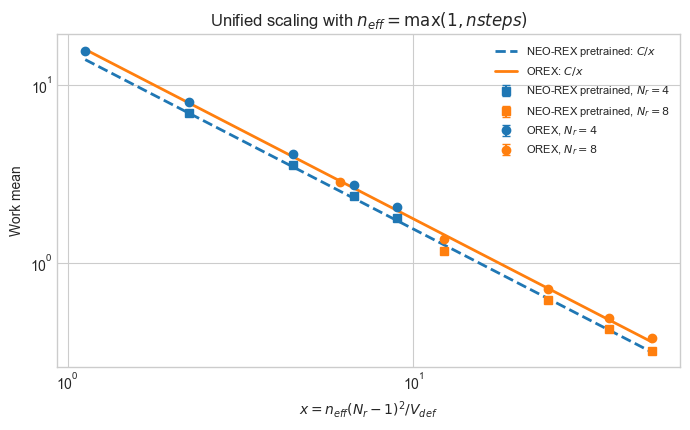

In [23]:
fig, ax = plt.subplots(figsize=(7.0, 4.4))
for algorithm, nrep, sub in by_algorithm_replica(unified):
    style = plot_style(algorithm, nrep)
    sub = sub.sort_values('unified_x')
    ax.errorbar(
        sub['unified_x'],
        sub['work_mean'],
        yerr=sub['work_sem'],
        marker=style['marker'],
        linestyle='none',
        color=style['color'],
        capsize=3,
        label=f'{algorithm}, $N_r={nrep}$',
    )

xmin = float(unified['unified_x'].min())
xmax = float(unified['unified_x'].max())
xs = np.geomspace(xmin, xmax, 300)
for _, fit in unified_fits.iterrows():
    algorithm = fit['algorithm']
    style = styles.get(algorithm, {'linestyle': '-'})
    ax.plot(xs, fit['C'] / xs, linestyle=style['linestyle'], linewidth=2.0,
            label=f'{algorithm}: $C/x$')

ax.set_xlabel(r'$x=n_{eff}(N_r-1)^2/V_{def}$')
ax.set_ylabel('Work mean')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title(r'Unified scaling with $n_{eff}=\max(1,nsteps)$')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
savefig(fig, 'raw_unified_neff_work_scaling_with_pt0')
plt.show()

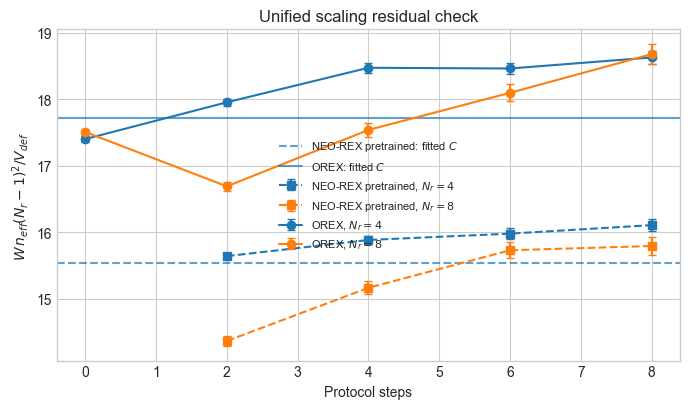

In [24]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
for algorithm, nrep, sub in by_algorithm_replica(unified):
    style = plot_style(algorithm, nrep)
    sub = sub.sort_values('nsteps')
    ax.errorbar(
        sub['nsteps'],
        sub['work_times_unified_x'],
        yerr=sub['work_times_unified_x_sem'],
        marker=style['marker'],
        linestyle=style['linestyle'],
        color=style['color'],
        capsize=3,
        label=f'{algorithm}, $N_r={nrep}$',
    )
for _, fit in unified_fits.iterrows():
    algorithm = fit['algorithm']
    style = styles.get(algorithm, {'linestyle': '-'})
    ax.axhline(fit['C'], linestyle=style['linestyle'], alpha=0.7,
               label=f'{algorithm}: fitted $C$')
ax.set_xlabel('Protocol steps')
ax.set_ylabel(r'$W\,n_{eff}(N_r-1)^2/V_{def}$')
ax.set_title('Unified scaling residual check')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
savefig(fig, 'raw_unified_neff_work_times_x_check_with_pt0')
plt.show()

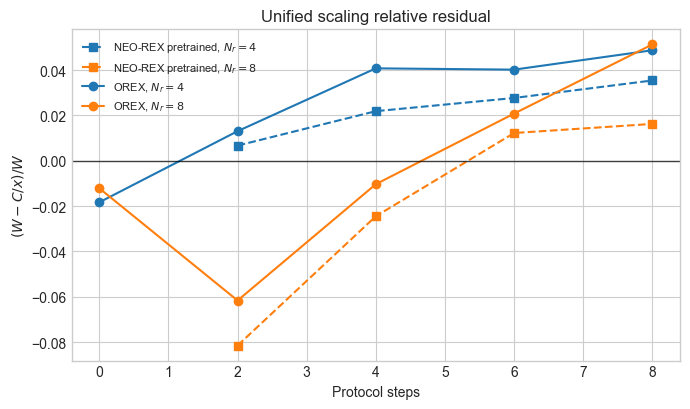

,algorithm,nreplicas,nsteps,nsteps_eff,unified_x,C,unified_prediction,work_mean,work_sem,unified_relative_residual,work_times_unified_x
0,NEO-REX pretrained,4,2,2.0,2.250,15.539743,6.906552,6.952978,0.021290,0.006677,15.644201
1,NEO-REX pretrained,4,4,4.0,4.500,15.539743,3.453276,3.530432,0.014540,0.021854,15.886944
2,NEO-REX pretrained,4,6,6.0,6.750,15.539743,2.302184,2.367685,0.011760,0.027665,15.981874
3,NEO-REX pretrained,4,8,8.0,9.000,15.539743,1.726638,1.789984,0.010170,0.035389,16.109856
4,NEO-REX pretrained,8,2,2.0,12.250,15.539743,1.268550,1.172992,0.005558,-0.081466,14.369152
5,NEO-REX pretrained,8,4,4.0,24.500,15.539743,0.634275,0.619129,0.003950,-0.024463,15.168668
6,NEO-REX pretrained,8,6,6.0,36.750,15.539743,0.422850,0.428084,0.003240,0.012227,15.732094
7,NEO-REX pretrained,8,8,8.0,49.000,15.539743,0.317138,0.322369,0.002788,0.016227,15.796061
8,OREX,4,0,1.0,1.125,17.721123,15.752109,15.468660,0.035250,-0.018324,17.402242
9,OREX,4,2,2.0,2.250,17.721123,7.876055,7.980036,0.023260,0.013030,17.955081


In [25]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
for algorithm, nrep, sub in by_algorithm_replica(unified):
    style = plot_style(algorithm, nrep)
    sub = sub.sort_values('nsteps')
    ax.plot(
        sub['nsteps'],
        sub['unified_relative_residual'],
        marker=style['marker'],
        linestyle=style['linestyle'],
        color=style['color'],
        label=f'{algorithm}, $N_r={nrep}$',
    )
ax.axhline(0.0, color='k', linewidth=1.0, alpha=0.7)
ax.set_xlabel('Protocol steps')
ax.set_ylabel(r'$(W-C/x)/W$')
ax.set_title('Unified scaling relative residual')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
savefig(fig, 'raw_unified_neff_relative_residual_with_pt0')
plt.show()

unified[[
    'algorithm', 'nreplicas', 'nsteps', 'nsteps_eff', 'unified_x', 'C',
    'unified_prediction', 'work_mean', 'work_sem', 'unified_relative_residual',
    'work_times_unified_x'
]].sort_values(['algorithm', 'nreplicas', 'nsteps'])